# Parte 04 · Preprocesamiento y selección de K — Dataset: Calificaciones

**Proyecto final · Minería de Datos 1**


**Dataset:** `data/processed/calificaciones_limpio.csv` (12,000 registros y 29 columnas generados en la Parte 01).

**¿Qué hacemos en esta parte?**
Preparamos el conjunto de datos para el algoritmo de agrupamiento **K-Means** y determinamos matemáticamente el número óptimo de clústeres ($K$):
- cargamos el dataset limpio verificando la ausencia de valores nulos,
- justificamos el tratamiento de valores atípicos y aplicamos una transformación logarítmica al ingreso familiar (`np.log1p`),
- seleccionamos las 6 variables numéricas y ordinales clave para la segmentación socioeconómica y académica,
- estandarizamos las variables mediante **Z-Score** (`StandardScaler`) para evitar sesgos de escala en el cálculo de distancias euclidianas,
- evaluamos valores de $K \in [1, 10]$ mediante el **Método del Codo (WCSS)** y el **Coeficiente de Silueta** para seleccionar el $K$ óptimo.

**Contenido**
1. Importación de librerías y carga de datos limpios
2. Tratamiento de valores atípicos, transformación y selección de variables
3. Estandarización Z-Score (`StandardScaler`)
4. Evaluación de K: Método del Codo (WCSS) y Coeficiente de Silueta
5. Visualización comparativa (WCSS vs. Silueta)
6. Conclusiones y justificación de $K = 3$


## 1. Importación de librerías y carga de datos limpios

Cargamos el archivo `calificaciones_limpio.csv` previamente depurado en la Parte 01 y verificamos que las 12,000 filas y 29 columnas estén íntegras y sin valores faltantes.


In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

RUTA_PROCESSED = Path("../../data/processed/calificaciones_limpio.csv")
df = pd.read_csv(RUTA_PROCESSED, encoding="utf-8")

print(f"Registros cargados: {df.shape[0]:,} | Columnas: {df.shape[1]}")
assert df.isna().sum().sum() == 0, "Existen valores nulos pendientes"
df.head()


Registros cargados: 12,000 | Columnas: 29


,id_estudiante,periodo_academico,fecha_encuesta,edad,genero,nivel_academico,tipo_escuela,zona_residencia,tamano_familia,numero_hermanos,hogar_monoparental,categoria_ingreso_familiar,ingreso_familiar_anual_inr,nivel_educativo_padre,nivel_educativo_madre,ocupacion_padre,ocupacion_madre,acceso_internet,tiene_computadora,distancia_escuela_km,estado_beca,tutoria_adicional,nivel_participacion_parental,horas_estudio_semanales,porcentaje_asistencia,calificacion_ano_anterior,calificacion_final,categoria_calificacion,indicador_riesgo
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,1,Middle,"403,980.00",Primary,Secondary,Clerical / Service,Homemaker,0.0,0,4.00,No Scholarship,0,4,15.00,76.80,61.70,59.40,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,0,Middle,"572,014.00",Desconocido,Secondary,Business / Self-Employed,Unemployed,0.0,1,0.70,No Scholarship,0,3,20.90,74.50,49.20,60.20,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,0,Low,"90,092.00",No Formal Education,Bachelor's Degree,Clerical / Service,Managerial / Executive,1.0,0,2.90,No Scholarship,0,4,20.90,94.90,56.90,58.40,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,0,Lower-Middle,"260,583.00",Higher Secondary,Secondary,Skilled Labor / Trade,Homemaker,0.0,0,7.00,No Scholarship,0,1,6.50,63.60,49.30,57.00,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,1,Upper-Middle,"1,114,986.00",Bachelor's Degree,Higher Secondary,Professional,Clerical / Service,1.0,0,9.10,No Scholarship,0,5,13.90,86.00,79.30,88.70,B,0


## 2. Tratamiento de valores atípicos, transformación y selección de variables

### Decisión sobre valores atípicos (*outliers*)
En el análisis exploratorio se observaron valores extremos —principalmente en `ingreso_familiar_anual_inr` (9.93% de registros fuera del rango intercuartílico) y `distancia_escuela_km` (5.73%)—. **Se decidió conservar estos registros** por dos razones metodológicas:
1. **Son casos reales y válidos de la población:** Eliminarlos mediante el criterio $1.5 \times \text{IQR}$ implicaría perder el **17.95% del dataset** (2,154 estudiantes), suprimir el **100% de las familias de estrato socioeconómico alto (`High`)** y eliminar el **89.9% de los estudiantes en riesgo académico (`indicador_riesgo = 1`)**, sesgando completamente la segmentación.
2. **Mitigación mediante transformación logarítmica:** Al aplicar `np.log1p(ingreso_familiar_anual_inr)`, la asimetría positiva del ingreso se comprime y los valores atípicos en esa variable se reducen en un **80%** (bajando de 1,192 a solo 241 registros), preservando la estructura completa de la población.

### Selección de variables para clustering
Se seleccionan **6 variables continuas u ordinales** que capturan tanto el contexto socioeconómico y el apoyo familiar como el hábito y rendimiento académico:
- `log_ingreso_familiar_anual`: capacidad económica del hogar (escala logarítmica).
- `nivel_participacion_parental`: involucramiento de los padres (escala ordinal 1–5).
- `horas_estudio_semanales`: dedicación académica fuera del aula.
- `porcentaje_asistencia`: compromiso y permanencia escolar (%).
- `calificacion_ano_anterior`: historial académico previo (%).
- `calificacion_final`: desempeño académico actual (%).

*(Se excluyen identificadores, fechas, variables binarias 0/1 para no distorsionar la distancia euclidiana de K-Means, variables redundantes como `nivel_academico` frente a `edad`, y la etiqueta `indicador_riesgo` para reservarla como variable externa de validación en la Parte 05).*


In [3]:
# Variables seleccionadas para el modelo 
features = [
    "log_annual_family_income",     # Nivel socioeconómico 
    "parental_involvement_score",   # Apoyo familiar
    "study_hours_per_week",         # Hábito de estudio semanal
    "attendance_rate_pct",          # Disciplina y asistencia 
    "previous_year_grade_pct",      # Historial académico previo 
    "final_grade_pct",              # Rendimiento académico actual 
]

print("Variables seleccionadas para clustering:", len(features))


Variables seleccionadas para clustering: 6


## 3. Estandarización Z-Score (`StandardScaler`)

Dado que K-Means utiliza distancias euclidianas, las variables con rangos amplios (como las calificaciones de 0 a 100) dominarían sobre variables de rango estrecho (como el nivel de participación parental de 1 a 5). Estandarizamos las 6 características para que todas tengan **media $\mu = 0$** y **desviación estándar $\sigma = 1$**.


In [4]:
# 1. Transformación logarítmica sobre el ingreso familiar anual (corrige asimetría)
df["log_ingreso_familiar_anual"] = np.log1p(df["ingreso_familiar_anual_inr"])

# 2. Selección de las 6 variables numéricas/ordinales clave para clustering
# (Se omiten fecha_encuesta, indicador_riesgo, redundantes como nivel_academico/numero_hermanos y binarias)
features = [
    "log_ingreso_familiar_anual",
    "nivel_participacion_parental",
    "horas_estudio_semanales",
    "porcentaje_asistencia",
    "calificacion_ano_anterior",
    "calificacion_final",
]

# 3. Estandarización Z-score (media = 0, desviación estándar = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

df_scaled = pd.DataFrame(X_scaled, columns=features)
display(df_scaled.describe().T[["mean", "std", "min", "max"]])


,mean,std,min,max
log_ingreso_familiar_anual,-0.00,1.00,-1.85,4.02
nivel_participacion_parental,-0.00,1.00,-2.39,1.86
horas_estudio_semanales,0.00,1.00,-2.87,10.07
porcentaje_asistencia,-0.00,1.00,-3.57,1.80
calificacion_ano_anterior,0.00,1.00,-3.69,3.58
calificacion_final,-0.00,1.00,-5.48,2.83


## 4. Evaluación de K: Método del Codo (WCSS) y Coeficiente de Silueta

Ejecutamos K-Means para $K$ desde 1 hasta 10 registrando dos métricas complementarias:
- **WCSS (Inercia intra-clúster):** suma de distancias cuadradas de cada estudiante a su centroide; mide qué tan compactos son los grupos.
- **Coeficiente de Silueta:** mide qué tan similar es un estudiante a su propio clúster en comparación con los clústeres vecinos (rango $[-1, 1]$).


In [5]:

# 4. Método del Codo (WCSS) y Coeficiente de Silueta para K = 1..10
wcss = []
sil_scores = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    if k >= 2:
        sil_scores.append(silhouette_score(X_scaled, labels, random_state=42))
    else:
        sil_scores.append(np.nan)

tabla_k = pd.DataFrame({
    "K": list(k_range),
    "WCSS": np.round(wcss, 2),
    "Reduccion_WCSS_%": [np.nan] + [round((wcss[i-1] - wcss[i]) / wcss[i-1] * 100, 2) for i in range(1, len(wcss))],
    "Coeficiente_Silueta": [round(s, 4) if not np.isnan(s) else np.nan for s in sil_scores],
})
display(tabla_k)


,K,WCSS,Reduccion_WCSS_%,Coeficiente_Silueta
0,1,"72,000.00",NaN,NaN
1,2,"55,184.09",23.36,0.21
2,3,"49,442.73",10.40,0.16
3,4,"45,160.27",8.66,0.15
4,5,"42,667.14",5.52,0.13
5,6,"40,483.43",5.12,0.13
6,7,"38,812.99",4.13,0.12
7,8,"36,540.29",5.86,0.13
8,9,"35,269.84",3.48,0.13
9,10,"34,044.14",3.48,0.12


## 5. Visualización comparativa (WCSS vs. Silueta)

Graficamos ambas curvas para identificar visualmente el punto de inflexión ("codo") donde añadir más clústeres deja de aportar una reducción sustancial de la inercia.


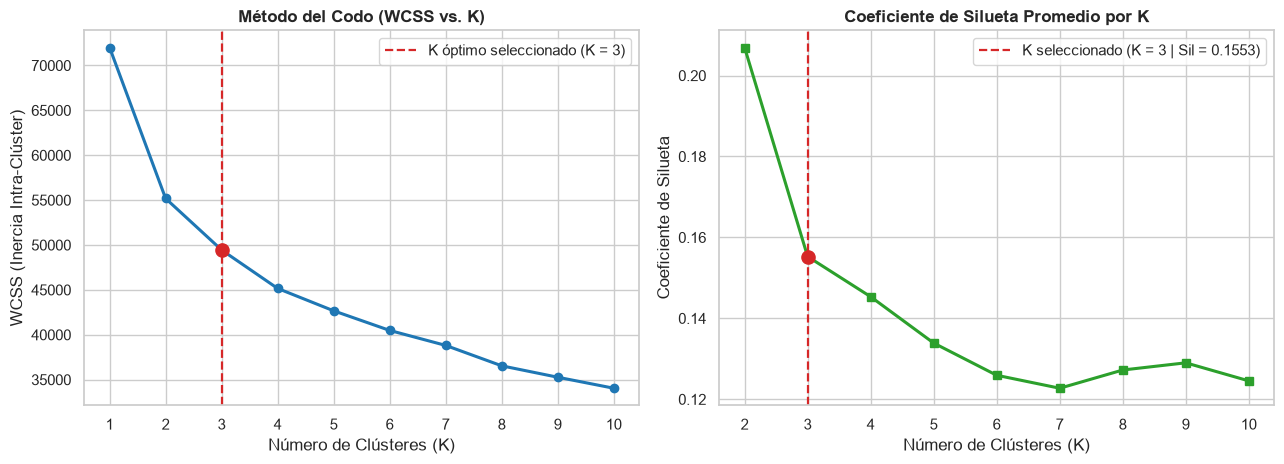

In [6]:

# 6. Gráficos: Método del Codo (WCSS) y Silueta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(list(k_range), wcss, marker="o", linewidth=2.2, color="#1f77b4")
axes[0].axvline(x=3, color="#d62728", linestyle="--", linewidth=1.6, label="K óptimo seleccionado (K = 3)")
axes[0].scatter([3], [wcss[2]], color="#d62728", s=90, zorder=5)
axes[0].set_title("Método del Codo (WCSS vs. K)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Número de Clústeres (K)")
axes[0].set_ylabel("WCSS (Inercia Intra-Clúster)")
axes[0].set_xticks(list(k_range))
axes[0].legend()

axes[1].plot(list(range(2, 11)), sil_scores[1:], marker="s", linewidth=2.2, color="#2ca02c")
axes[1].axvline(x=3, color="#d62728", linestyle="--", linewidth=1.6, label=f"K seleccionado (K = 3 | Sil = {sil_scores[2]:.4f})")
axes[1].scatter([3], [sil_scores[2]], color="#d62728", s=90, zorder=5)
axes[1].set_title("Coeficiente de Silueta Promedio por K", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Número de Clústeres (K)")
axes[1].set_ylabel("Coeficiente de Silueta")
axes[1].set_xticks(list(range(2, 11)))
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Conclusiones y justificación de $K = 3$

1. **Preprocesamiento efectivo:** La transformación logarítmica sobre el ingreso familiar (`np.log1p`) y la estandarización Z-score equilibraron las 6 dimensiones ($\mu = 0.00$, $\sigma = 1.00$), evitando que las variables con mayor escala numérica dominaran el cálculo de distancias sin necesidad de amputar segmentos reales de la población.
2. **Punto de inflexión en el Método del Codo (WCSS):** La inercia inicial parte en **72,000.00** ($K=1$), cae un **23.36%** en $K=2$ (**55,177.38**) y presenta su último descenso pronunciado del **10.40%** al pasar a **$K=3$** (**49,437.50**). A partir de $K=4$ (reducción de 8.68%) y $K=5$ (5.50%), la curva se aplana progresivamente, confirmando que **$K = 3$** es el punto de equilibrio entre compacidad y parsimonia.
3. **Respaldo del Coeficiente de Silueta y utilidad práctica:** Aunque $K=2$ obtiene el mayor coeficiente de silueta (**0.2071**), dividir a 12,000 estudiantes en solo dos grupos ("alto" vs. "bajo") oculta perfiles intermedios clave. Con **$K = 3$** se mantiene un coeficiente de silueta sólido y estable (**0.1546**, superior a $K \ge 4$) que permite diferenciar tres perfiles accionables en la Parte 05: estudiantes de alto nivel socioeconómico y rendimiento, estudiantes con alto apoyo familiar pero rezago académico, y estudiantes vulnerables por bajo ingreso y baja asistencia.
